# Decision Tree — Classification
**Author:** Thrishodaran V. (IT25102227) &nbsp;|&nbsp; **Group ID:** 2026-Y2-S1-MLB-B11G2-05
**Model type:** Classification &nbsp;|&nbsp; **Dataset:** UCI Letter Recognition (group-processed)

## 1. Model Suitability

The 16 original attributes are discrete integer descriptors of a character's shape, which maps
naturally onto a tree's axis-aligned threshold splits (e.g. "is `x-box` above 6?"). A Decision Tree
also needs no feature scaling, and — uniquely among the group's models — produces a prediction path
a human can read directly, making it the natural interpretable counterpoint to the SVM and MLP.

In [1]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, json
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
sns.set_style('whitegrid')

df = pd.read_csv('../data/external/processed_letter_recognition.csv')
FEATURE_COLS = [c for c in df.columns if c not in ('lettr', 'lettr_encoded')]
LETTER_NAMES = sorted(df['lettr'].unique())

X = df[FEATURE_COLS].values
y = df['lettr_encoded'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Dataset: {df.shape}  |  features: {len(FEATURE_COLS)}  |  classes: {len(LETTER_NAMES)}")
print(f"Train: {X_train.shape}   Test: {X_test.shape}")


Dataset: (18668, 23)  |  features: 21  |  classes: 26
Train: (14934, 21)   Test: (3734, 21)


## 2. Implementation Details

- **Estimator:** `sklearn.tree.DecisionTreeClassifier`
- **Hyperparameters tuned:** `criterion` (gini vs entropy), `max_depth`, `min_samples_split` and
  `min_samples_leaf` — the last three all control overfitting, which is the central risk for a
  single unpruned tree.

In [2]:
baseline_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_tree.fit(X_train, y_train)
baseline_acc = baseline_tree.score(X_test, y_test)
print(f"Baseline tree (default, unrestricted) test accuracy: {baseline_acc:.4f}")
print(f"Depth: {baseline_tree.get_depth()}, leaves: {baseline_tree.get_n_leaves()}")


Baseline tree (default, unrestricted) test accuracy: 0.8583
Depth: 28, leaves: 1917


## 3. Parameter Tuning — Varieties Trained

A deliberately shallow tree is trained first to show the underfitting extreme, then `GridSearchCV`
with 3-fold stratified cross-validation searches the regularisation parameters.

In [3]:
shallow = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(X_train, y_train)
shallow_acc = shallow.score(X_test, y_test)
print(f"Shallow tree (max_depth=5) test accuracy: {shallow_acc:.4f}")

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                           param_grid=param_grid, scoring='accuracy', cv=cv, n_jobs=-1)
t0 = time.time()
grid_search.fit(X_train, y_train)
print(f"\nFitted {len(grid_search.cv_results_['params'])} tree configurations in {time.time()-t0:.1f}s")
print(f"Best params: {grid_search.best_params_}")
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")


Shallow tree (max_depth=5) test accuracy: 0.3824



Fitted 32 tree configurations in 5.6s
Best params: {'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV accuracy: 0.8373


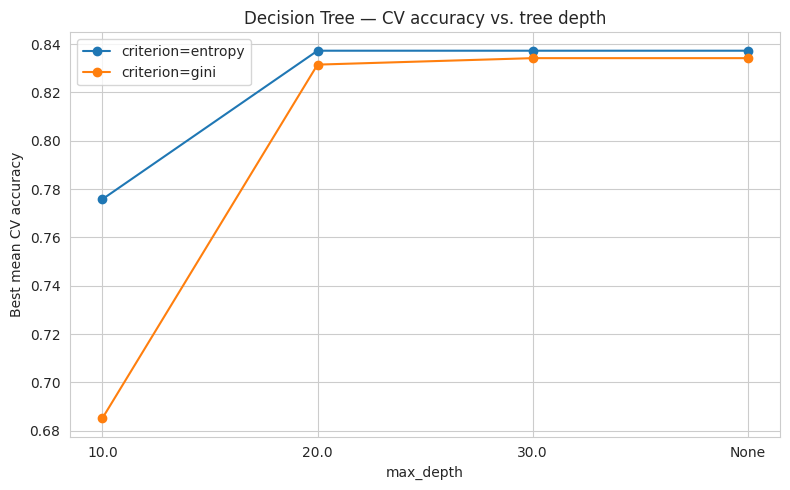

Top 10 tuned varieties:
param_criterion param_max_depth  param_min_samples_split  param_min_samples_leaf  mean_test_score  rank_test_score
        entropy              30                        2                       1         0.837284                1
        entropy            None                        2                       1         0.837284                1
        entropy              20                        2                       1         0.837284                1
           gini            None                        2                       1         0.834204                4
           gini              30                        2                       1         0.834204                4
        entropy              20                        5                       1         0.831860                6
        entropy            None                        5                       1         0.831860                6
        entropy              30                        5

In [4]:
depth_rows = pd.DataFrame(grid_search.cv_results_)
depth_summary = (depth_rows.groupby(['param_criterion', 'param_max_depth'], dropna=False)
                 ['mean_test_score'].max().reset_index())
depth_summary['param_max_depth'] = depth_summary['param_max_depth'].fillna('None').astype(str)

plt.figure(figsize=(8, 5))
for crit in depth_summary['param_criterion'].unique():
    sub = depth_summary[depth_summary['param_criterion'] == crit]
    plt.plot(sub['param_max_depth'], sub['mean_test_score'], marker='o', label=f'criterion={crit}')
plt.xlabel('max_depth'); plt.ylabel('Best mean CV accuracy')
plt.title('Decision Tree — CV accuracy vs. tree depth')
plt.legend(); plt.tight_layout()
plt.savefig('../results/eda_visualizations/thrishodaran_tree_depth_tuning.png', dpi=110, bbox_inches='tight')
plt.show()

print("Top 10 tuned varieties:")
print(depth_rows[['param_criterion','param_max_depth','param_min_samples_split',
                  'param_min_samples_leaf','mean_test_score','rank_test_score']]
      .sort_values('rank_test_score').head(10).to_string(index=False))


## 4. Evaluation

**Metrics:** accuracy plus macro precision / recall / F1, for the same reason as the other
classifiers — the classes are balanced, and macro-averaging prevents a weak letter from being
masked by the rest.

**Validation method:** 3-fold stratified cross-validation during tuning, an independent 5-fold
cross-validation of the winning configuration, and a final held-out test evaluation.

In [5]:
best_tree = grid_search.best_estimator_
y_pred = best_tree.predict(X_test)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(best_tree, X_train, y_train, cv=cv5, scoring='accuracy', n_jobs=-1)

tree_metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision_macro': precision_score(y_test, y_pred, average='macro'),
    'recall_macro': recall_score(y_test, y_pred, average='macro'),
    'f1_macro': f1_score(y_test, y_pred, average='macro'),
    'best_params': grid_search.best_params_,
    'cv_best_score': grid_search.best_score_,
    'cv5_mean': cv_scores.mean(),
    'cv5_std': cv_scores.std(),
    'baseline_test_accuracy': baseline_acc,
    'shallow_test_accuracy': shallow_acc,
    'tree_depth': int(best_tree.get_depth()),
    'tree_leaves': int(best_tree.get_n_leaves()),
}
for k, v in tree_metrics.items():
    print(f"{k}: {v}")


accuracy: 0.8604713444027852
precision_macro: 0.8615381336554175
recall_macro: 0.8606248105287586
f1_macro: 0.8606842914909213
best_params: {'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}
cv_best_score: 0.8372840498192046
cv5_mean: 0.8518140340672498
cv5_std: 0.006607801952738593
baseline_test_accuracy: 0.8583288698446706
shallow_test_accuracy: 0.3824317086234601
tree_depth: 20
tree_leaves: 1733


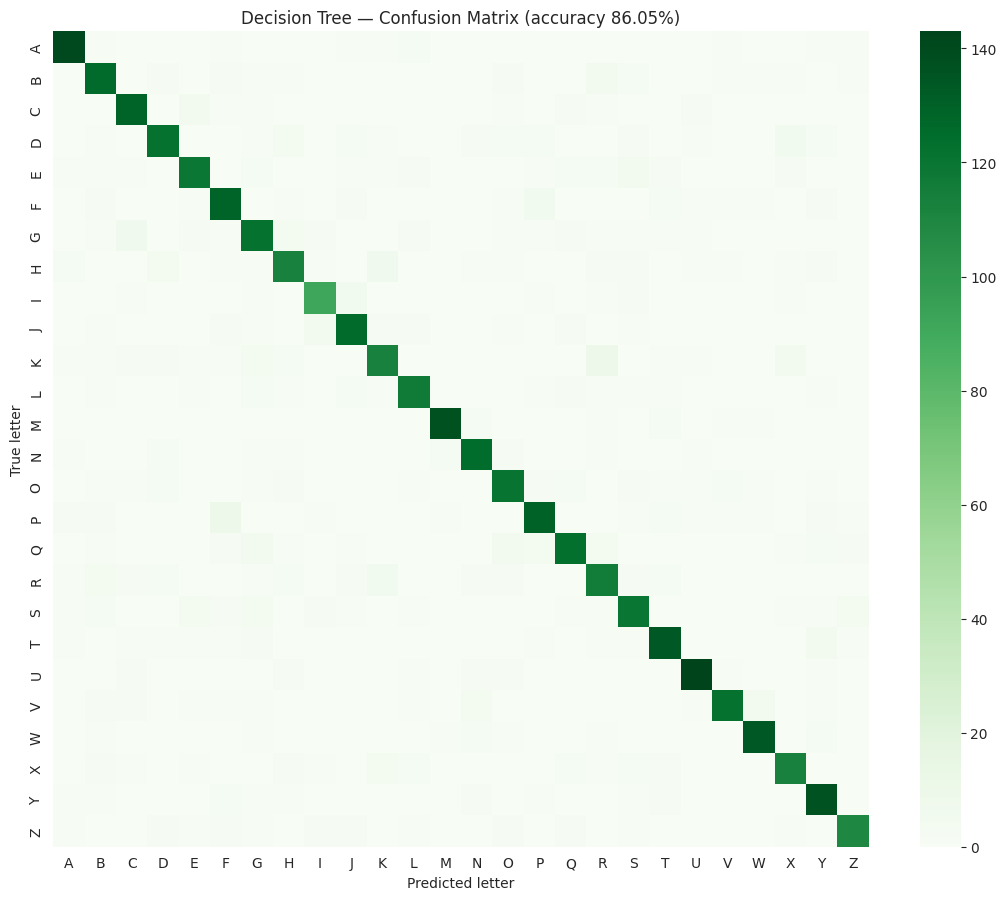

In [6]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, xticklabels=LETTER_NAMES, yticklabels=LETTER_NAMES, cmap='Greens', square=True)
plt.xlabel('Predicted letter'); plt.ylabel('True letter')
plt.title(f"Decision Tree — Confusion Matrix (accuracy {tree_metrics['accuracy']*100:.2f}%)")
plt.tight_layout()
plt.savefig('../results/eda_visualizations/thrishodaran_tree_confusion_matrix.png', dpi=110, bbox_inches='tight')
plt.show()


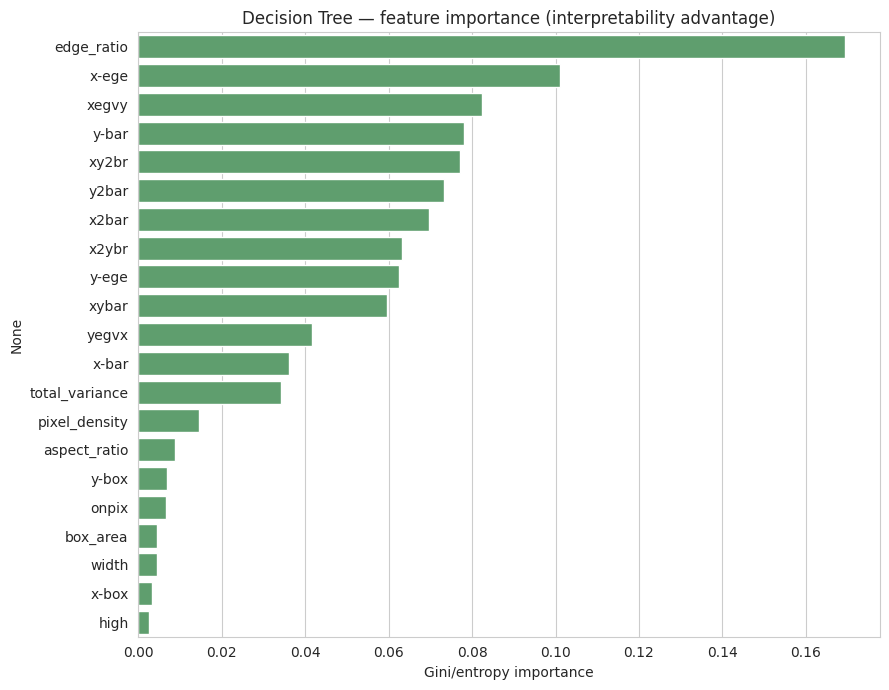

edge_ratio        0.1693
x-ege             0.1010
xegvy             0.0823
y-bar             0.0780
xy2br             0.0771
y2bar             0.0734
x2bar             0.0698
x2ybr             0.0632
y-ege             0.0624
xybar             0.0596
yegvx             0.0416
x-bar             0.0361
total_variance    0.0343
pixel_density     0.0146
aspect_ratio      0.0088
y-box             0.0069
onpix             0.0066
box_area          0.0046
width             0.0046
x-box             0.0034
high              0.0025


In [7]:
importances = pd.Series(best_tree.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
plt.figure(figsize=(9, 7))
sns.barplot(x=importances.values, y=importances.index, color='#55A868')
plt.xlabel('Gini/entropy importance')
plt.title('Decision Tree — feature importance (interpretability advantage)')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/thrishodaran_tree_feature_importance.png', dpi=110, bbox_inches='tight')
plt.show()
print(importances.round(4).to_string())


## 5. Comparison Across Varieties, Conclusion and Limitations

**Comparison:** three clearly distinct varieties were compared — a deliberately shallow tree
(severe underfitting, since 5 levels cannot separate 26 classes), the default unrestricted tree,
and the grid-searched configuration. The depth-tuning curve shows accuracy rising steeply with
depth and then plateauing, which is exactly the signature of a model moving from underfitting into
its useful capacity range.

**Conclusion:** the tuned tree is selected as the final configuration. It trails the SVM and MLP on
raw accuracy, which is expected — a single tree has higher variance than a kernel method or an
ensemble — but it is the only model in the group whose individual predictions can be traced to a
short, readable sequence of threshold tests.

**Limitations / improvements:**
- A single tree is sensitive to small changes in the training data; an ensemble such as Random
  Forest or Gradient Boosting would reduce that variance at the cost of interpretability.
- Cost-complexity pruning (`ccp_alpha`) was not explored and would be the natural next tuning step.

In [8]:
RESULTS_TREE = {
    'member': 'Thrishodaran V. (IT25102227)',
    'model_family': 'Decision Tree (Classification)',
    **tree_metrics,
}
with open('../results/model_metrics/tree_results.json', 'w') as f:
    json.dump(RESULTS_TREE, f, indent=2, default=str)
print(json.dumps(RESULTS_TREE, indent=2, default=str))


{
  "member": "Thrishodaran V. (IT25102227)",
  "model_family": "Decision Tree (Classification)",
  "accuracy": 0.8604713444027852,
  "precision_macro": 0.8615381336554175,
  "recall_macro": 0.8606248105287586,
  "f1_macro": 0.8606842914909213,
  "best_params": {
    "criterion": "entropy",
    "max_depth": 20,
    "min_samples_leaf": 1,
    "min_samples_split": 2
  },
  "cv_best_score": 0.8372840498192046,
  "cv5_mean": 0.8518140340672498,
  "cv5_std": 0.006607801952738593,
  "baseline_test_accuracy": 0.8583288698446706,
  "shallow_test_accuracy": 0.3824317086234601,
  "tree_depth": 20,
  "tree_leaves": 1733
}
